# Faz 2 - Keşifsel Veri Analizi (EDA)

Veri: NREL PVDAQ sistem 4 (Golden, CO), 2015-2016, 1 dk çözünürlüklü **gerçek** ölçümler, nominal kapasite 1 kW. Bu notebook yalnızca anlatır; grafik mantığı `src/eda.py` içindedir. Yorumlardaki sayılar aşağıdaki `stats` çıktısından gelir.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
import json
import pandas as pd
from IPython.display import Image
from src import config, data, eda
config.apply_plot_style()
%matplotlib inline
print(config.summary())

Yıllar: 2015-2016
Ham parquet: C:\Users\user\Desktop\merve\data\raw\pvdaq_sys4_2015_2016.parquet
Bölme: train 1 segment, val 6 segment, test 6 segment; veri sonu 2016-12-13 00:00
Hedef: ac_power [W]
Kapasite: 1.0 kW = 1000.0 W (nRMSE paydası: CAPACITY_W)


## Veri yükleme ve sayısal özet

In [2]:
raw = data.load_raw()
clean, cstats = data.clean_minutely(raw)
grid = data.load_grid()
stats = eda.eda_stats(raw, cstats, grid)
print(json.dumps(stats, ensure_ascii=False, indent=2))

{
  "gece_poa_median_ham": -2.76,
  "sentinel_sayilari": {
    "ac_power": 0,
    "poa_irradiance": 4,
    "ambient_temp": 2,
    "module_temp_1": 26748
  },
  "uc_negatif_poa_sayisi": 1,
  "uc_negatif_poa_min": -1078.6,
  "ambient_maks_ham": 68.57,
  "ac_kapasite_ustu_dakika": 460,
  "ac_poa_korelasyonu": 0.9776,
  "poa_tepe_saati_medyan": 11.88,
  "hesaplanan_guney_oglesi_ortalama": 12.01,
  "poa_pozitif_ama_yukselme_negatif_orani": 0.0001,
  "aralik_14_sonrasi_poa500_ac_medyan": 3.06,
  "hafta_yakinlastirma": [
    "2015-06-17",
    "2015-06-23"
  ],
  "acik_gun": "2016-06-15",
  "bulutlu_gun": "2016-06-30",
  "gunduz_ortalama_ac": 369.6,
  "eksik_oran_yuzde": {
    "ac_power": 0.0,
    "poa_irradiance": 0.0,
    "ambient_temp": 0.0,
    "module_temp_1": 2.541
  },
  "grid_satir": 68352
}


In [3]:
from IPython.display import Markdown, display


def tr(x, nd=1):
    '''Türkçe ondalık virgül biçimi.'''
    return f"{x:.{nd}f}".replace(".", ",")


def tr_int(n):
    '''Binlik ayracı nokta olan tam sayı.'''
    return f"{int(n):,}".replace(",", ".")


## Veri kesme kararı (2016-12-13)

Veri **2016-12-13 00:00**'da kesilmiştir. Gerekçe: 13 Aralık'tan itibaren `module_temp_1` sürekli eksik, 14 Aralık'tan itibaren invertör kapalıdır; ışınım yüksekken AC güç neredeyse sıfırda kalır (sayısal değer aşağıda yazdırılır). Bu günlerde ışınımdan güç tahmin edilemez; modeli yanıltacağı için dışarıda bırakıldı. Aşağıdaki grafik ham (kesilmemiş) Aralık verisini ve kesme çizgisini gösterir.

eda_10_aralik_2016_ariza.png


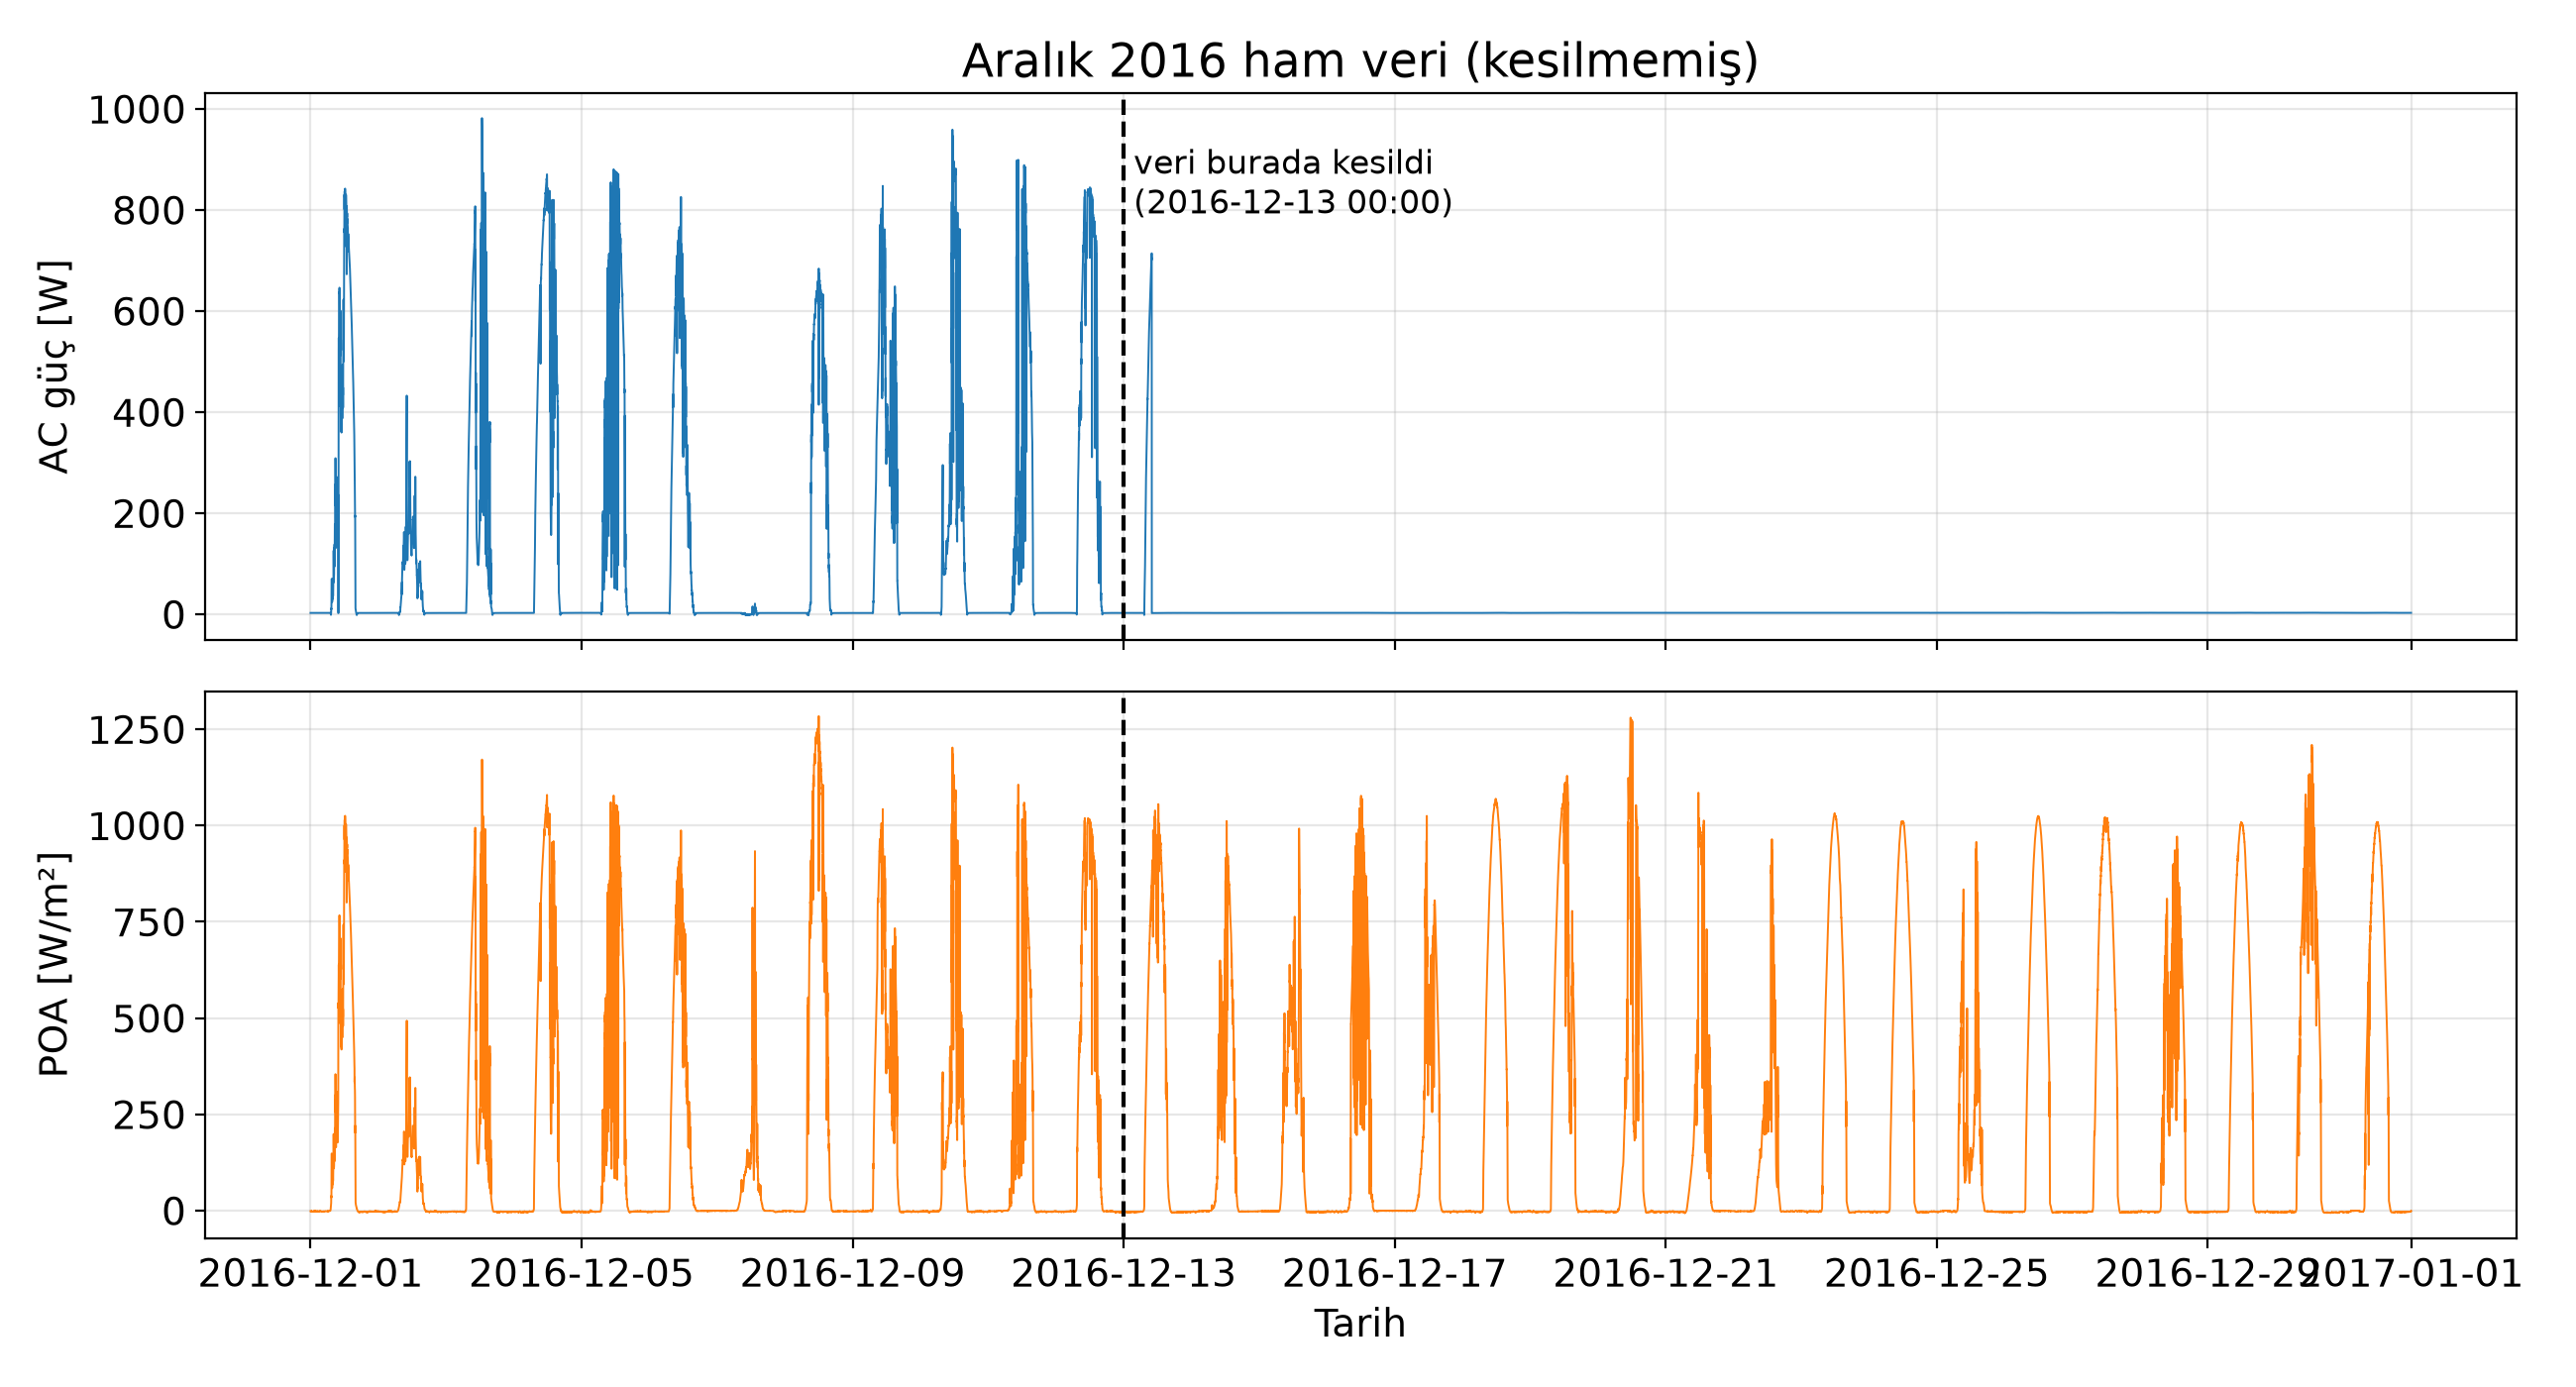

In [4]:
p = eda.plot_december_fault(raw)
print(p.name)
Image(filename=str(p))

In [5]:
print(config.DATA_END_REASON)
print('14 Aralık sonrası POA>500 iken AC medyanı [W]:', stats['aralik_14_sonrasi_poa500_ac_medyan'])

2016-12-13 10:13'ten itibaren module_temp_1 sürekli eksik ve 2016-12-14'ten itibaren invertör kapalı (POA 1000+ W/m² iken AC ≈ 3 W); bu günler fiziksel olarak tahmin edilemez. Kullanıcı kararıyla veri 2016-12-13 00:00'da kesildi; Aralık test segmenti 12 gündür.
14 Aralık sonrası POA>500 iken AC medyanı [W]: 3.06


## 1. Zaman serisi

Günlük ortalama AC güç ve POA 2015-2016 boyunca mevsimsel bir salınım gösterir; kışın düşük, yaz ve erken sonbaharda yüksektir. AC güç ile POA arasındaki korelasyon çok yüksektir (aşağıda yazdırılır), yani ışınım gücün ana belirleyicisidir. Kısa süreli düşüşler bulut, kar veya invertör olaylarına işaret eder (örn. Şubat 2015).

In [6]:
p = eda.plot_time_series(grid)
print(p.name)
Image(filename=str(p))
print('AC-POA korelasyonu:', stats['ac_poa_korelasyonu'])

eda_01_zaman_serisi.png
AC-POA korelasyonu: 0.9776


## 2. Bir haftalık yakınlaştırma

Haziran 2015'in en güneşli ardışık 7 günü seçilmiştir (tarihler aşağıda). AC güç ışınımı neredeyse birebir izler; bulutlu saatlerde ikisi birlikte oynar. Kesikli çizgiler her gün için hesaplanan güneş öğlesidir; POA tepeleri bu çizgilerin çok yakınında, hafifçe solunda yer alır.

In [7]:
p = eda.plot_week_zoom(grid)
print(p.name)
Image(filename=str(p))
print(stats['hafta_yakinlastirma'])

eda_02_hafta_yakinlastirma.png
['2015-06-17', '2015-06-23']


### Saat dilimi notu

In [8]:
fark_dk = (stats['hesaplanan_guney_oglesi_ortalama'] - stats['poa_tepe_saati_medyan']) * 60
display(Markdown(
    "Zaman damgası sabit yerel standart saat (**UTC-7**, DST yok) varsayılmıştır. Günlük POA tepe saatinin "
    f"medyanı yaklaşık {tr(stats['poa_tepe_saati_medyan'], 2)}; hesaplanan güneş öğlesi ortalaması yaklaşık "
    f"**{tr(stats['hesaplanan_guney_oglesi_ortalama'], 2)}**. Fark yaklaşık {tr(abs(fark_dk), 0)} dakikadır; "
    f"POA>20 iken güneş yüksekliği ≤ 0 olan satır oranı {tr(stats['poa_pozitif_ama_yukselme_negatif_orani']*100, 2)}% "
    "(ihmal edilebilir düzeyde). Tepenin biraz erken olması panel eğim/azimutundan ve bulut etkisinden "
    "kaynaklanabilir. Kesin zaman ofseti bu veriyle doğrulanamamıştır; UTC-7 çalışma varsayımıdır."))

Zaman damgası sabit yerel standart saat (**UTC-7**, DST yok) varsayılmıştır. Günlük POA tepe saatinin medyanı yaklaşık 11,88; hesaplanan güneş öğlesi ortalaması yaklaşık **12,01**. Fark yaklaşık 8 dakikadır; POA>20 iken güneş yüksekliği ≤ 0 olan satır oranı 0,01% (ihmal edilebilir düzeyde). Tepenin biraz erken olması panel eğim/azimutundan ve bulut etkisinden kaynaklanabilir. Kesin zaman ofseti bu veriyle doğrulanamamıştır; UTC-7 çalışma varsayımıdır.

In [9]:
print('POA tepe saati medyanı:', stats['poa_tepe_saati_medyan'])
print('Hesaplanan güneş öğlesi ortalaması:', stats['hesaplanan_guney_oglesi_ortalama'])
print('POA>20 ve yükseklik<=0 oranı:', stats['poa_pozitif_ama_yukselme_negatif_orani'])

POA tepe saati medyanı: 11.88
Hesaplanan güneş öğlesi ortalaması: 12.01
POA>20 ve yükseklik<=0 oranı: 0.0001


## 3. Günlük profil (mevsime göre)

Gün içi üretim çan biçimindedir ve öğle civarında tepe yapar. Yaz profili hem daha yüksek hem daha geniştir (uzun gün); kış profili alçak ve dardır. Bu nedenle saat ve yılın günü öznitelikleri modelde anlamlıdır.

eda_03_gunluk_profil.png


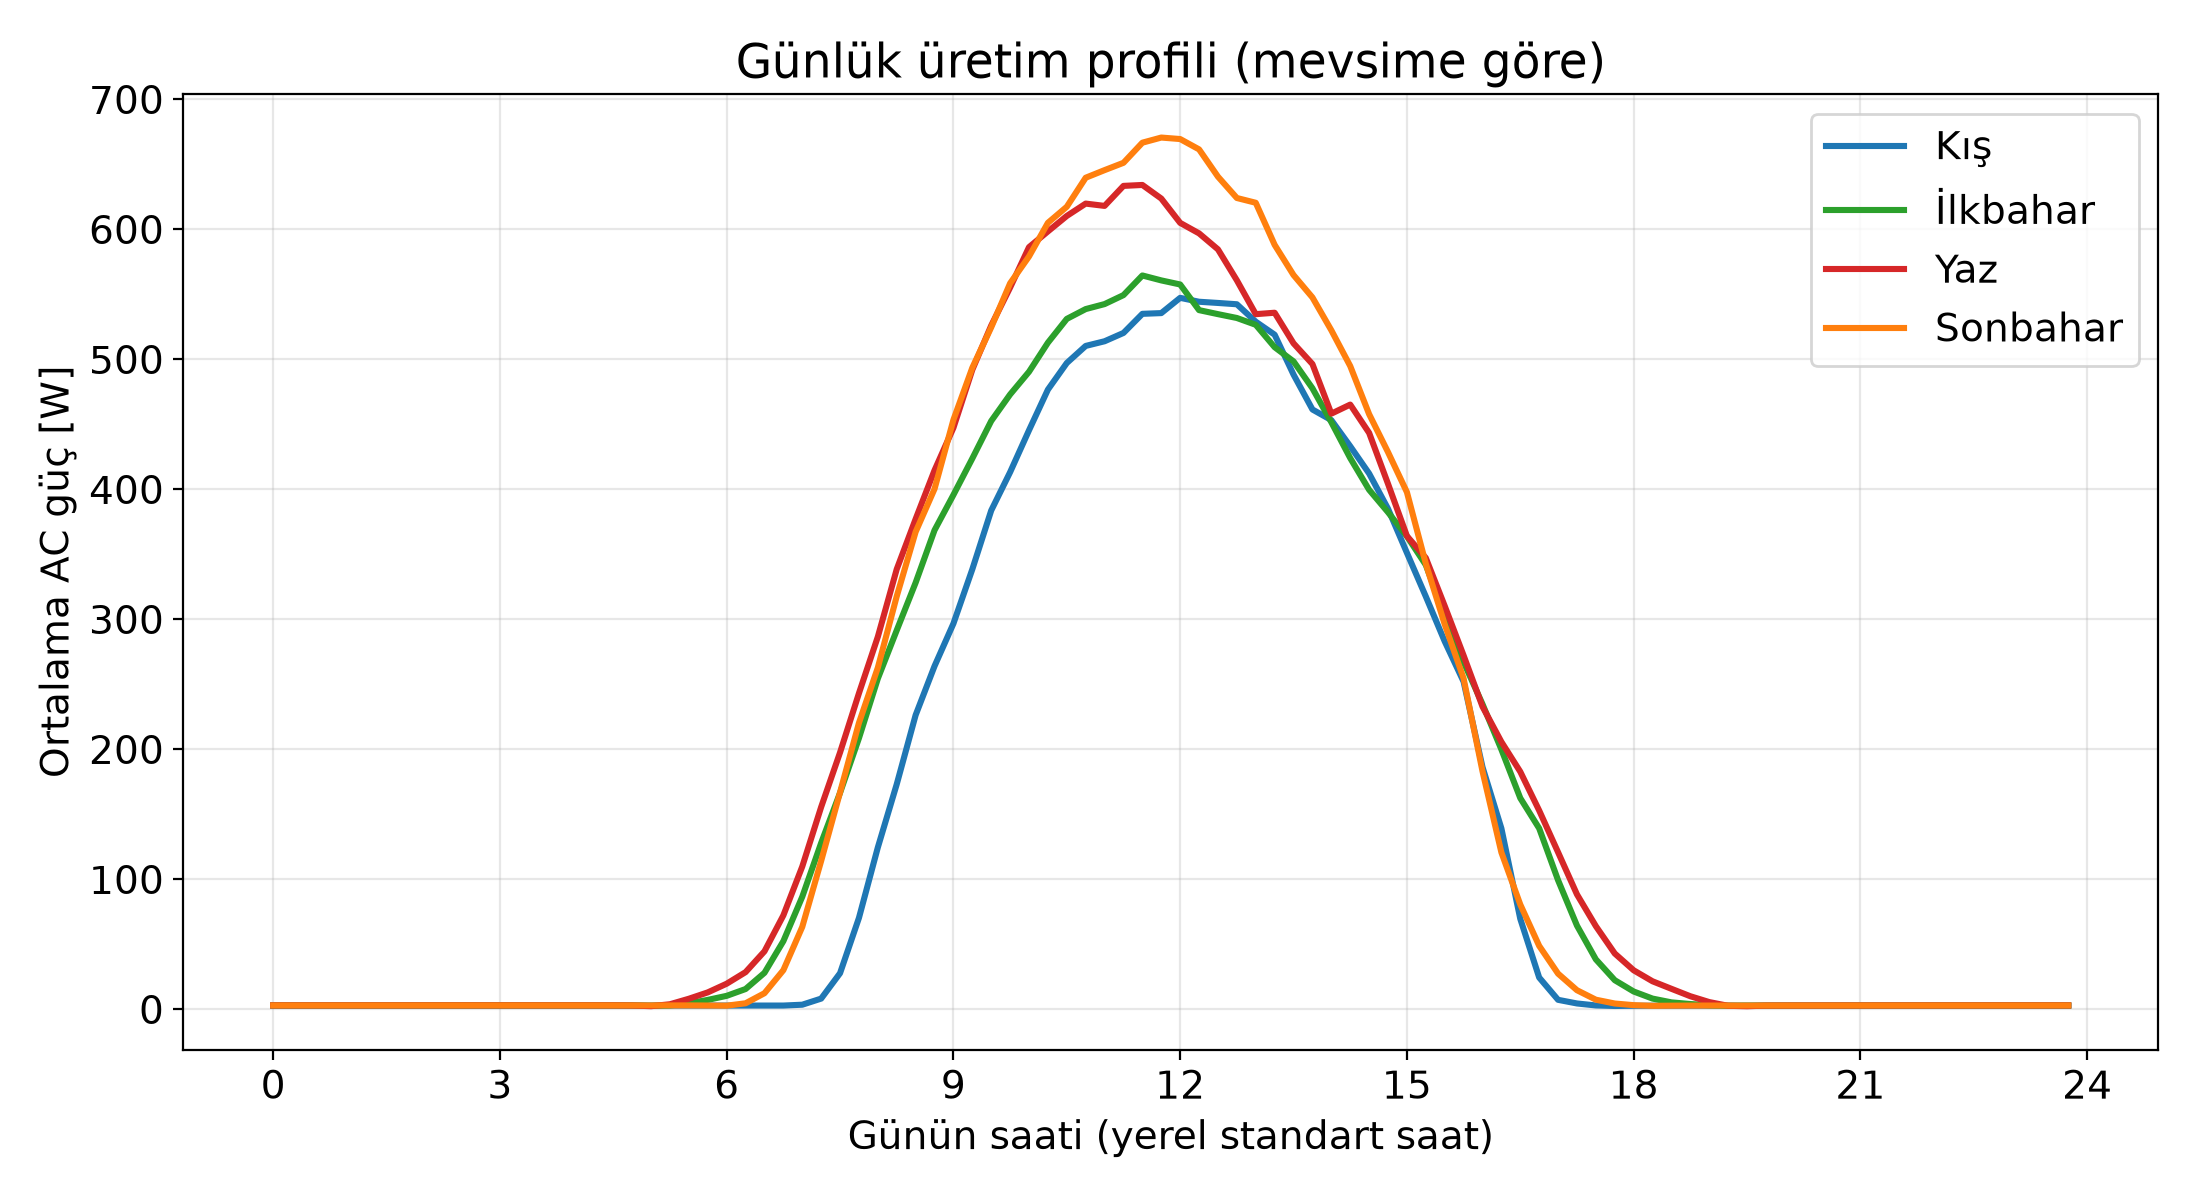

In [10]:
p = eda.plot_daily_profile(grid)
print(p.name)
Image(filename=str(p))

## 4. Aylık profil

Günlük ortalama enerji kışın düşük, yaz ve erken sonbaharda yüksektir (değerler grafikte). İki yıl arasında aynı ayda bile belirgin fark vardır (örn. Ocak ve Şubat 2015 2016'dan düşüktür); bu, hava koşulu ve olaylardan kaynaklanır. Aralık 2016 yalnızca veri kesme tarihine kadarki günleri içerir (gün ataması bin başlangıcına göre yapılır).

eda_04_aylik_profil.png


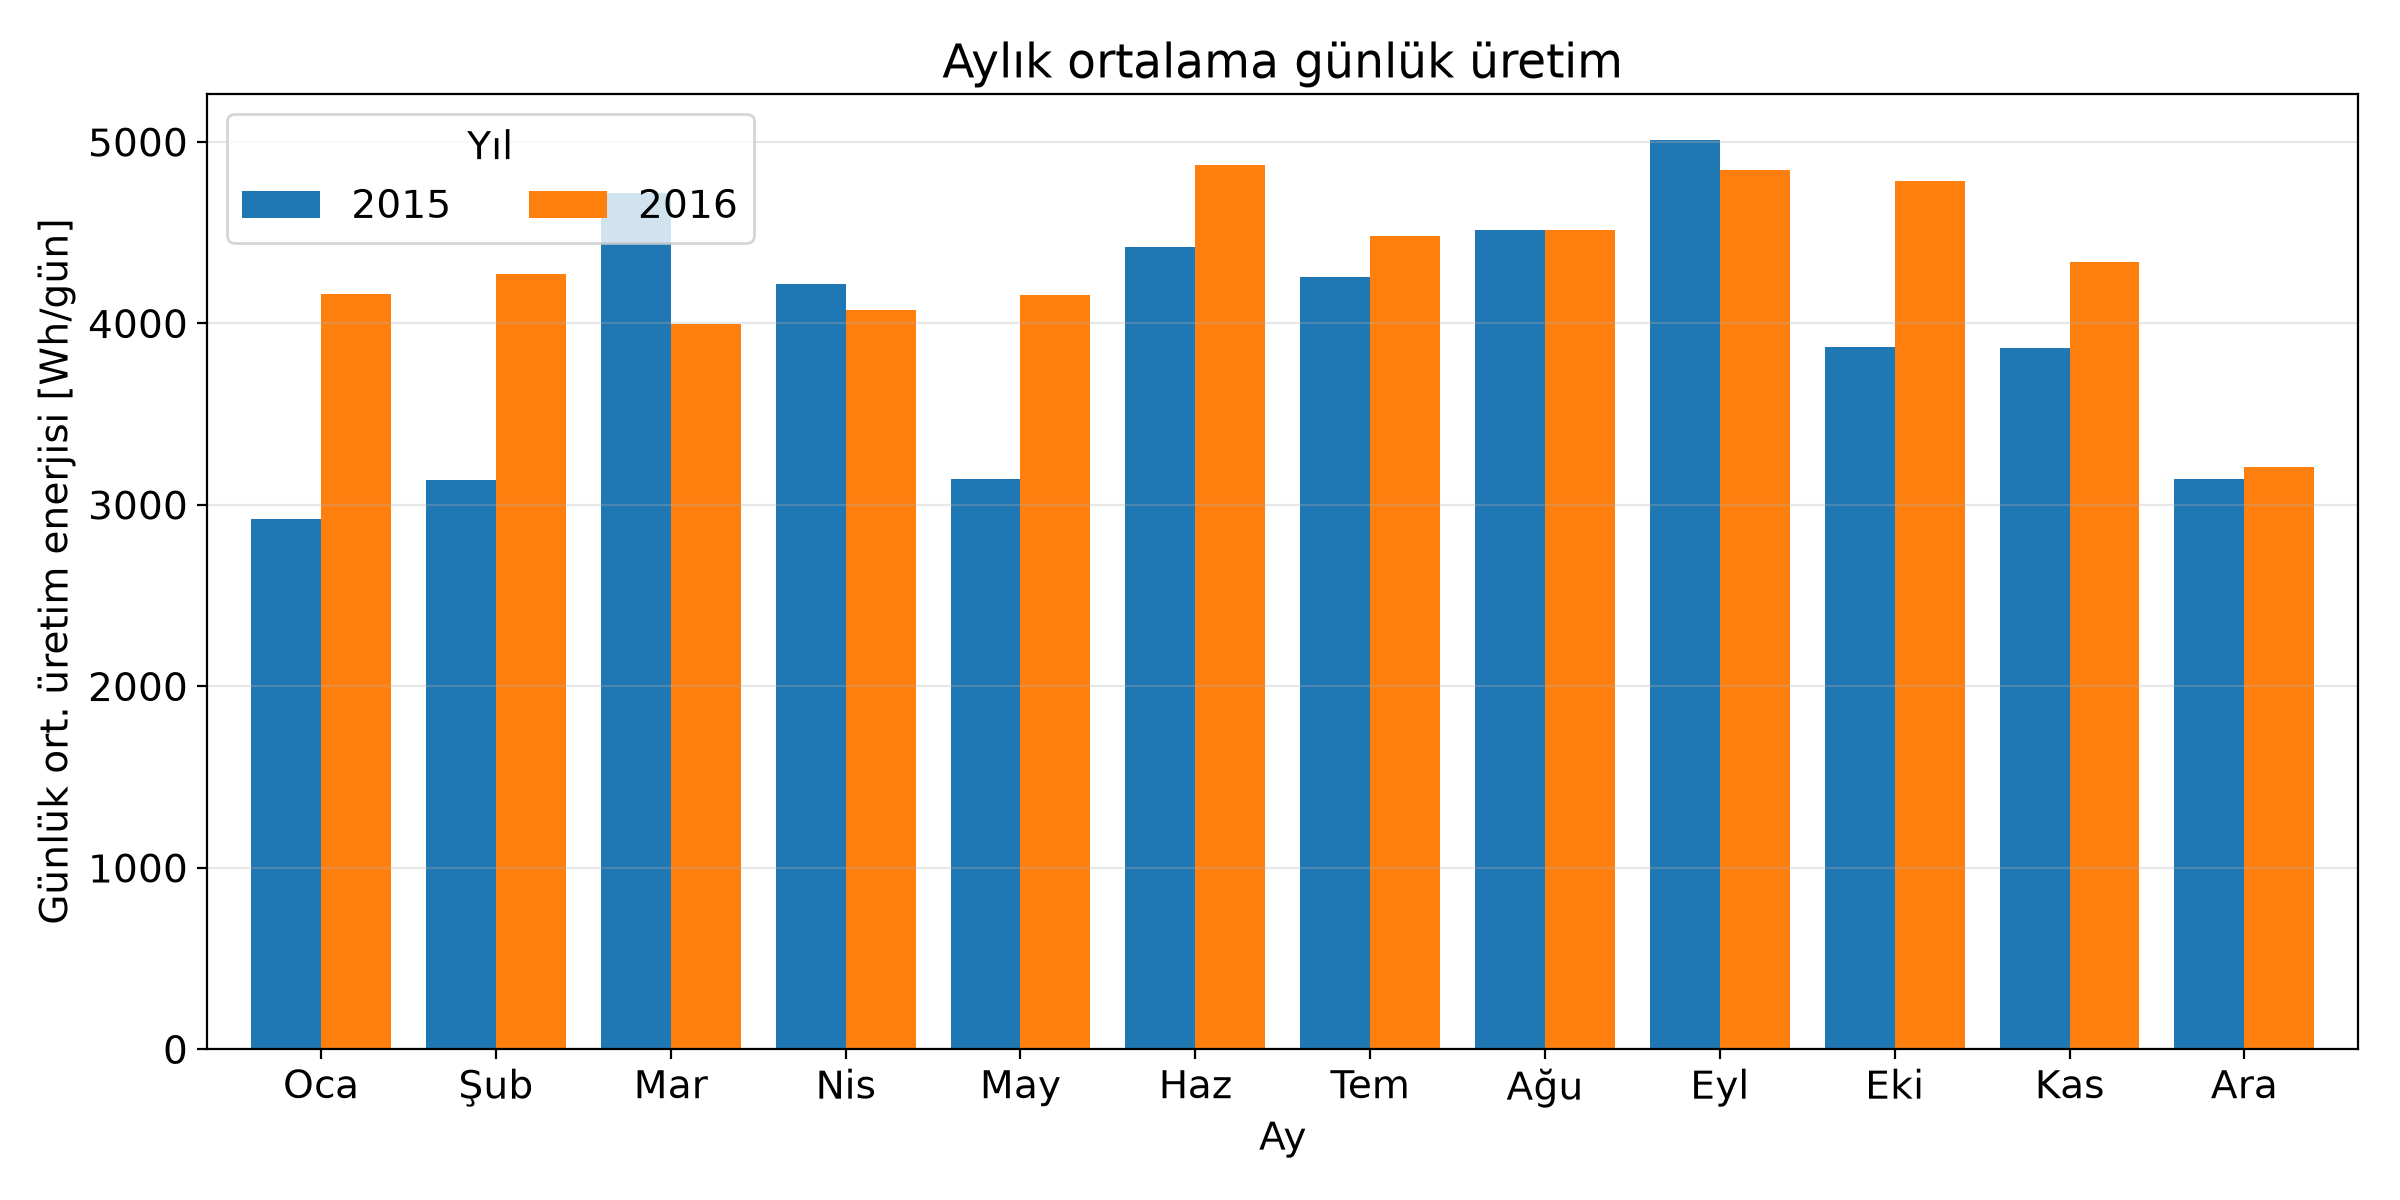

In [11]:
p = eda.plot_monthly_profile(grid)
print(p.name)
Image(filename=str(p))

## 5. Korelasyon matrisi

AC güç, POA ve modül sıcaklığı birbirleriyle güçlü pozitif ilişkilidir; ortam sıcaklığı daha zayıf ilişkilidir. Saat/yılın günü sin-cos çiftleri tek başına doğrusal korelasyonda düşük görünebilir ama döngüsel yapıyı taşırlar; güneş yüksekliği güçle yüksek korelasyon verir.

eda_05_korelasyon.png


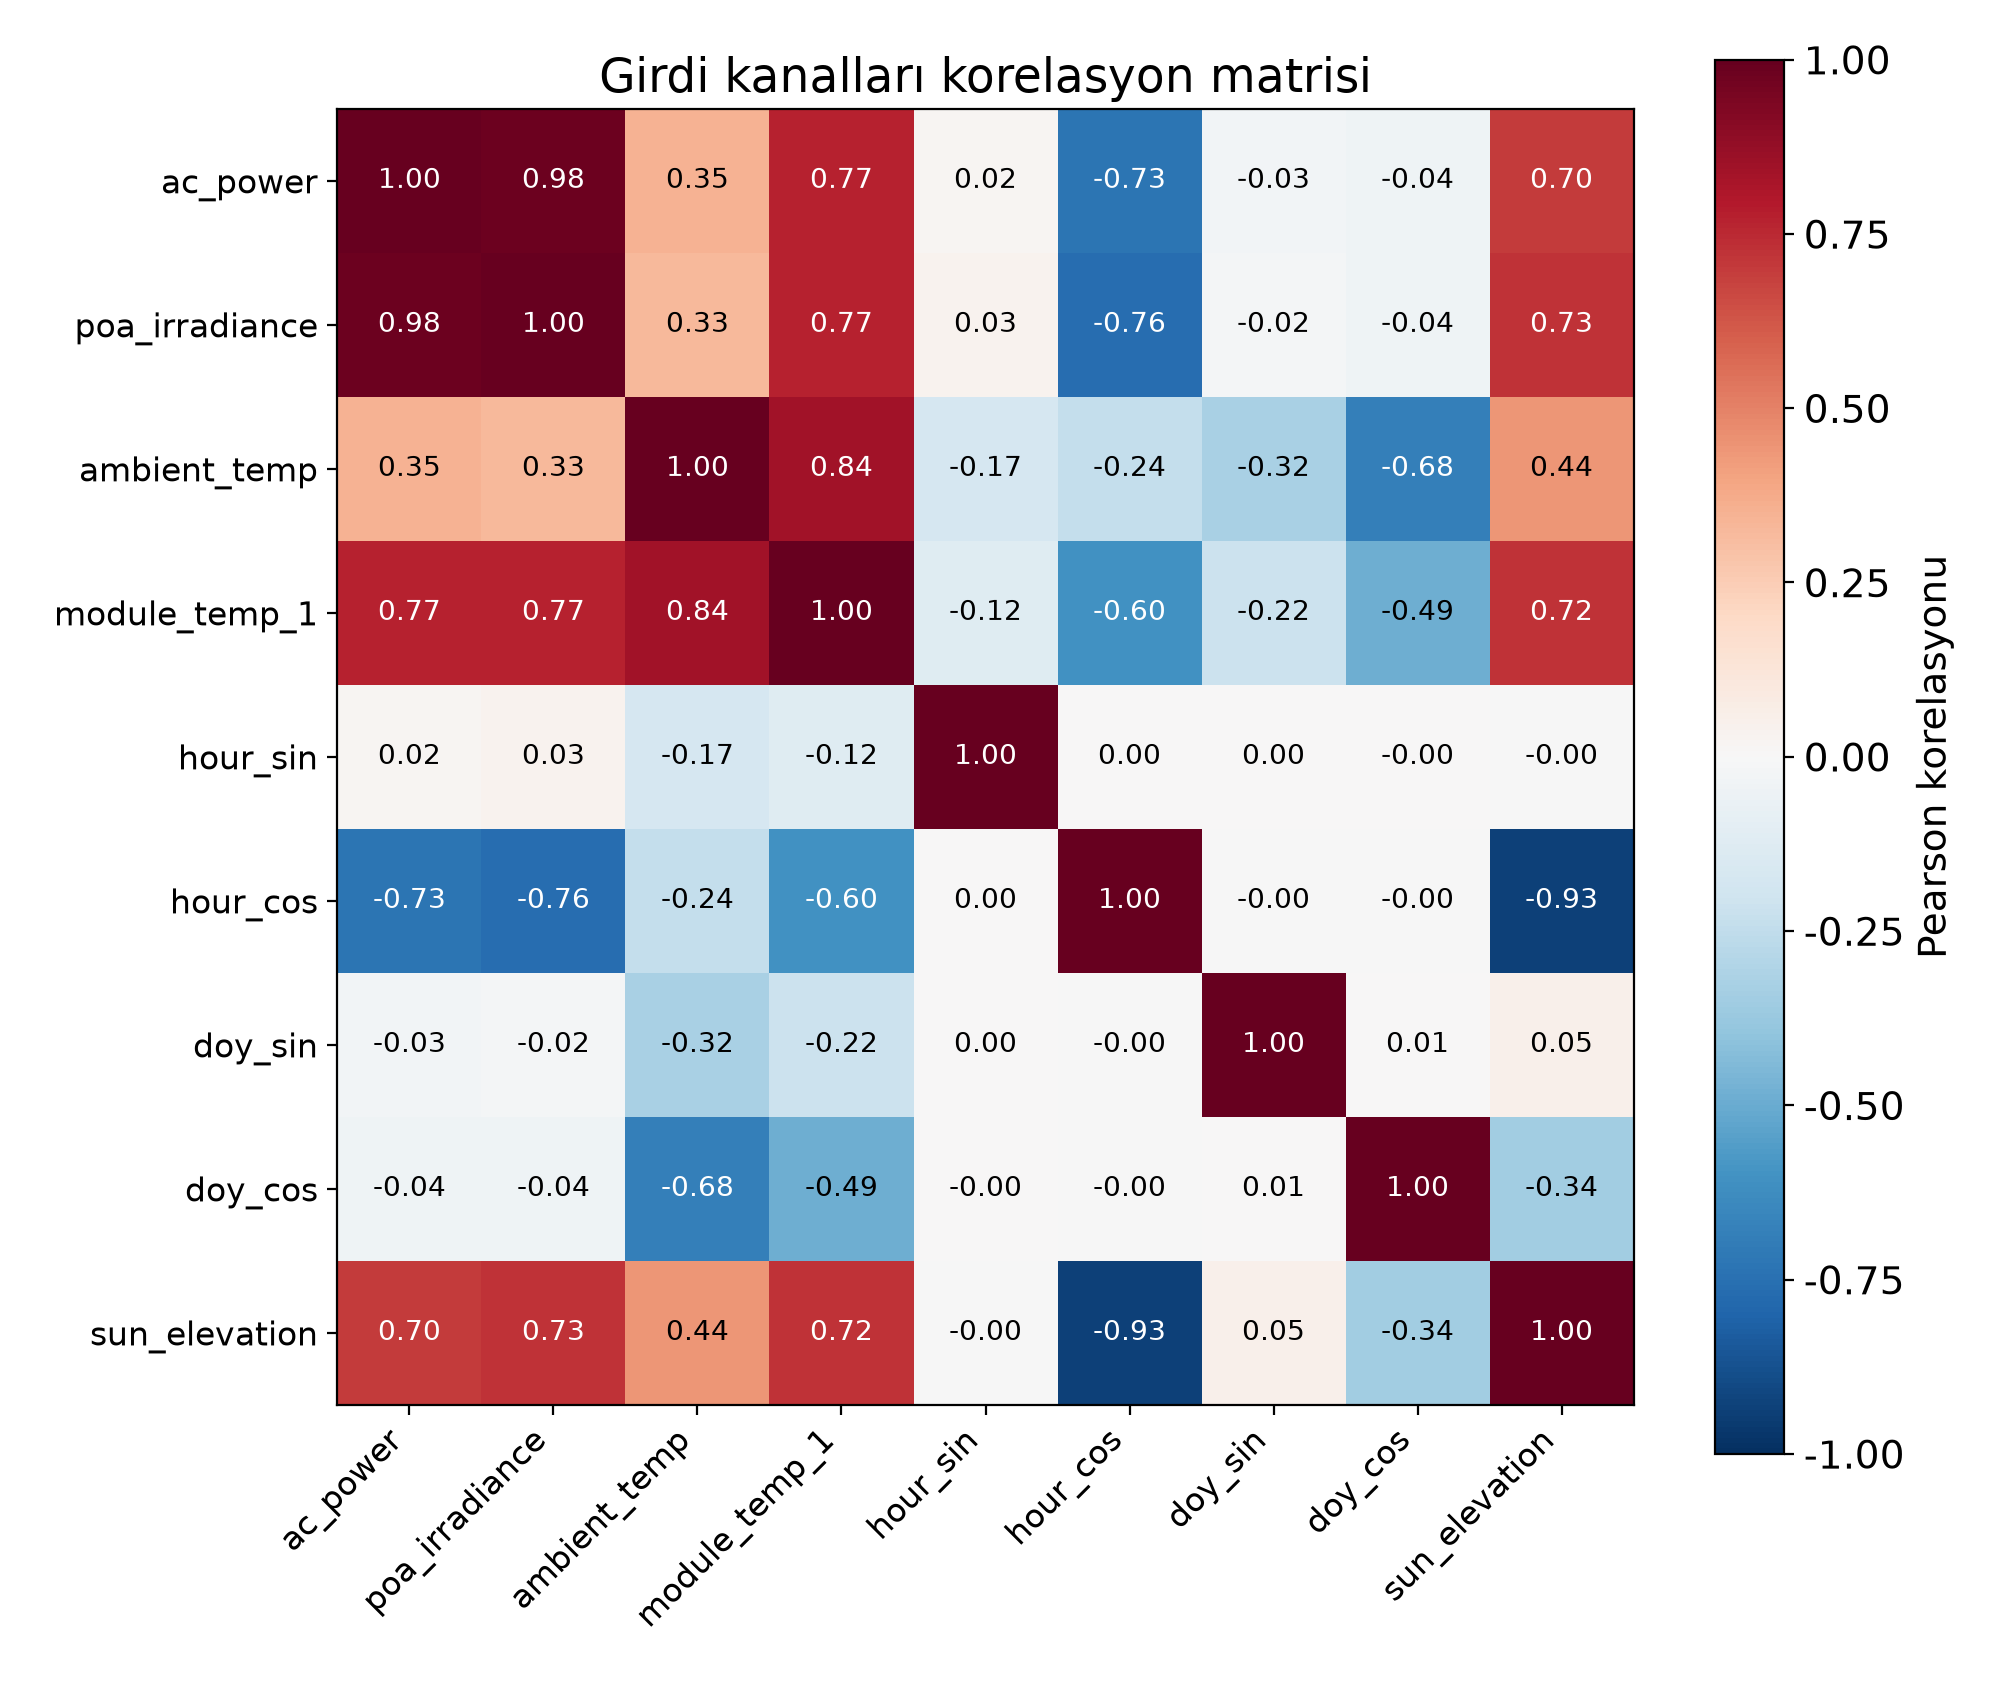

In [12]:
p = eda.plot_correlation(grid)
print(p.name)
Image(filename=str(p))

## 6. Güç - ışınım saçılımı

Gündüz satırlarında AC güç ışınımla yaklaşık doğrusal artar (korelasyon yukarıda). Aynı ışınımda saçılma modül sıcaklığına göre renk farkı olarak görülür: sıcak modüller verimi düşürür. Yatay çizgi nominal kapasiteyi gösterir (değer grafikte etiketlidir).

eda_06_guc_isinim_sacilim.png


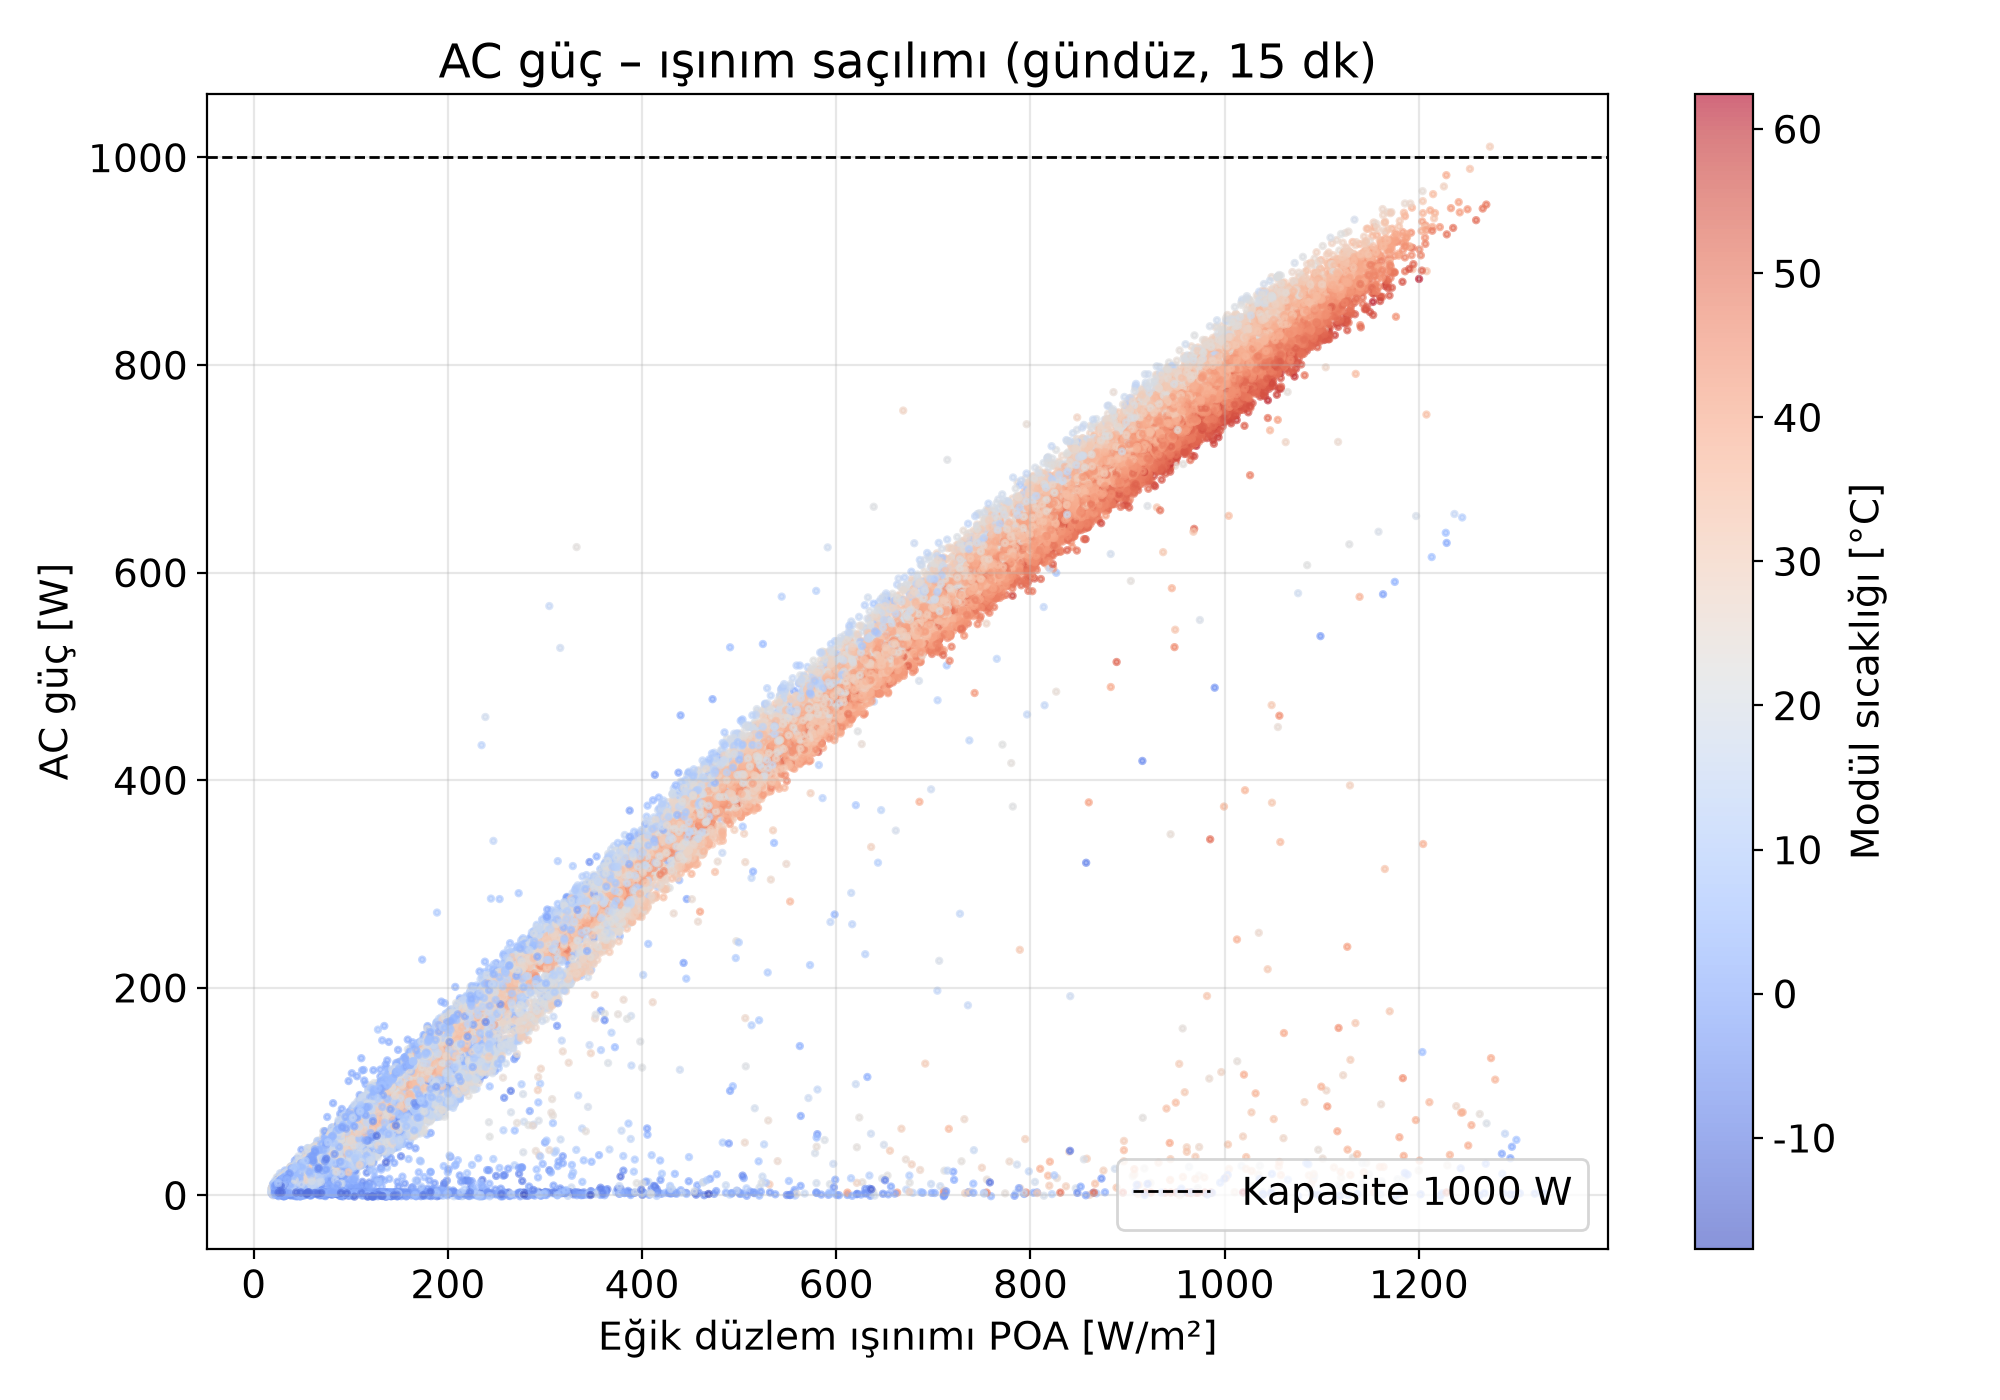

In [13]:
p = eda.plot_power_vs_irradiance(grid)
print(p.name)
Image(filename=str(p))

### Kapasite kırpılması notu

In [14]:
n_ust = stats['ac_kapasite_ustu_dakika']
if n_ust is not None:
    oran = 100 * n_ust / len(raw)
    display(Markdown(
        f"Ham veride AC güç nominal kapasiteyi ({tr(config.CAPACITY_W, 0)} W) aşan dakika sayısı **{tr_int(n_ust)}** "
        f"(toplamın %{tr(oran, 2)}'si). Bu değerler olası bir invertör sınırı/kırpılma ya da ölçüm "
        "belirsizliğine işaret edebilir; ayrıntılı analiz kapsam dışıdır, değerler silinmemiştir."))
print('AC > kapasite dakika:', n_ust)

Ham veride AC güç nominal kapasiteyi (1000 W) aşan dakika sayısı **460** (toplamın %0,04'si). Bu değerler olası bir invertör sınırı/kırpılma ya da ölçüm belirsizliğine işaret edebilir; ayrıntılı analiz kapsam dışıdır, değerler silinmemiştir.

AC > kapasite dakika: 460


## 7. Eksik veri özeti

In [15]:
eo = stats['eksik_oran_yuzde']
display(Markdown(
    "Temizlik sonrası, veri kesmeden önce eksik oranları (1 dk): "
    + ", ".join(f"`{k}` %{tr(v, 2)}" for k, v in eo.items())
    + ". `module_temp_1` eksiklerinin büyük bölümü Aralık 2016'nın sonunda toplanır; kesme kararıyla bu blok "
    "dışarıda kalır."))

Temizlik sonrası, veri kesmeden önce eksik oranları (1 dk): `ac_power` %0,00, `poa_irradiance` %0,00, `ambient_temp` %0,00, `module_temp_1` %2,54. `module_temp_1` eksiklerinin büyük bölümü Aralık 2016'nın sonunda toplanır; kesme kararıyla bu blok dışarıda kalır.

eda_07_eksik_veri.png


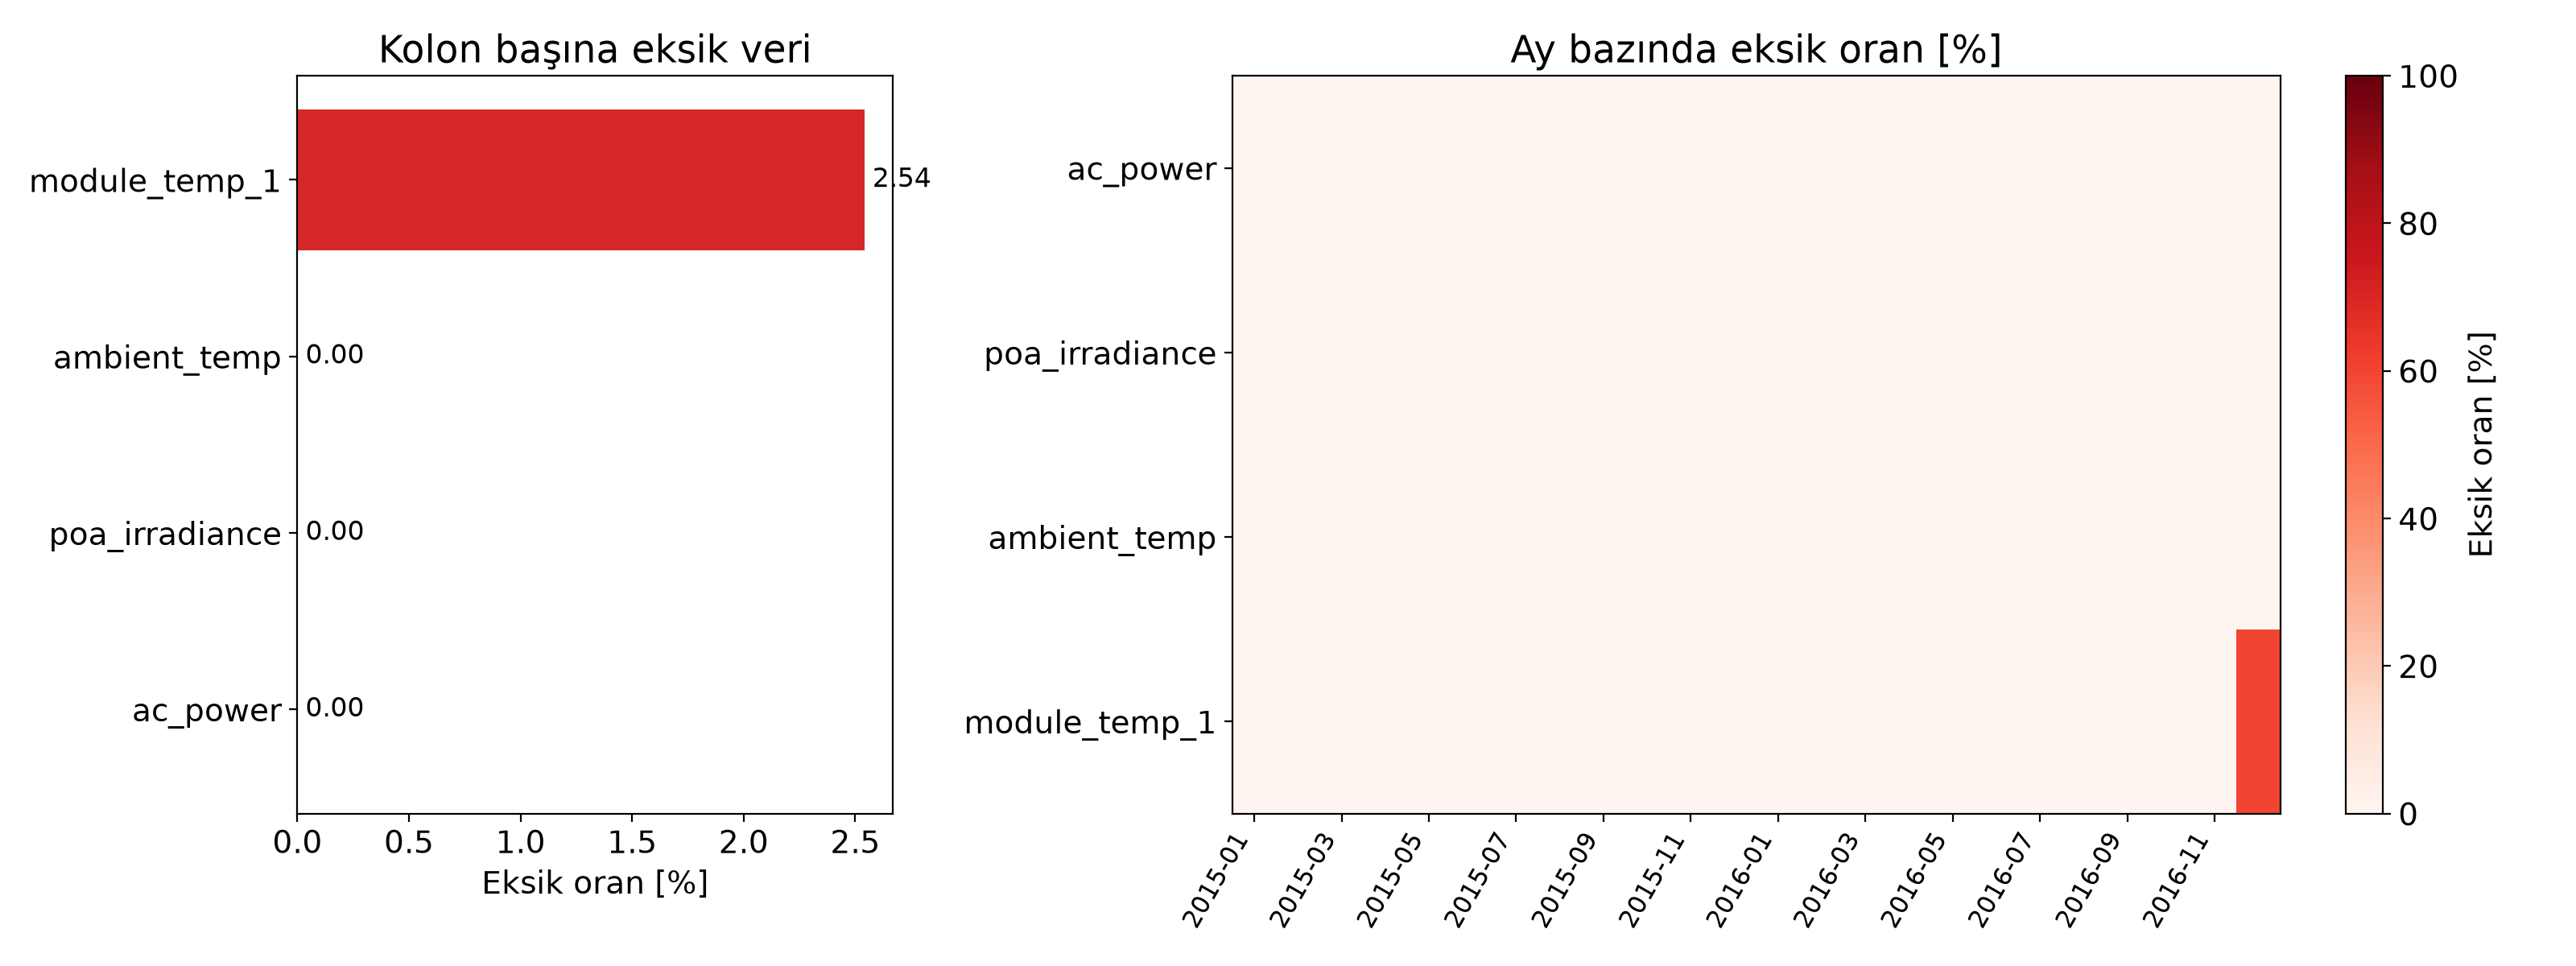

In [16]:
p = eda.plot_missing(clean, grid)
print(p.name)
Image(filename=str(p))

## 8. Temizlik öncesi / sonrası

In [17]:
sc = stats['sentinel_sayilari']
display(Markdown(
    "Ham gece POA değerleri sensör ofsetinden dolayı negatiftir "
    f"(medyan yaklaşık {tr(stats['gece_poa_median_ham'], 1)} W/m²); temizlik bunları 0'a çeker. "
    f"-7999 eksik işareti: `module_temp_1` {tr_int(sc['module_temp_1'])}, `poa_irradiance` {sc['poa_irradiance']}, "
    f"`ambient_temp` {sc['ambient_temp']}. {stats['uc_negatif_poa_sayisi']} uç negatif POA "
    f"(min {tr(stats['uc_negatif_poa_min'], 1)}) ve ham ortam sıcaklığı maksimumu "
    f"{tr(stats['ambient_maks_ham'], 2)} °C NaN yapılır; ≤ 2 adımlık boşluklar geçmiş değerle (ffill) doldurulur."))

Ham gece POA değerleri sensör ofsetinden dolayı negatiftir (medyan yaklaşık -2,8 W/m²); temizlik bunları 0'a çeker. -7999 eksik işareti: `module_temp_1` 26.748, `poa_irradiance` 4, `ambient_temp` 2. 1 uç negatif POA (min -1078,6) ve ham ortam sıcaklığı maksimumu 68,57 °C NaN yapılır; ≤ 2 adımlık boşluklar geçmiş değerle (ffill) doldurulur.

In [18]:
p = eda.plot_cleaning_before_after(raw, clean)
print(p.name)
Image(filename=str(p))
print('Gece POA medyanı (ham):', stats['gece_poa_median_ham'])
print(stats['sentinel_sayilari'])
print('Uç negatif POA:', stats['uc_negatif_poa_sayisi'], stats['uc_negatif_poa_min'])
print('Ortam maks (ham):', stats['ambient_maks_ham'])

eda_08_temizlik_oncesi_sonrasi.png
Gece POA medyanı (ham): -2.76
{'ac_power': 0, 'poa_irradiance': 4, 'ambient_temp': 2, 'module_temp_1': 26748}
Uç negatif POA: 1 -1078.6
Ortam maks (ham): 68.57


## 9. Bulutlu ve açık gün

Haziran 2016'dan günlük POA integrali en yüksek (açık) ve en düşük (ama arıza olmayan) gün seçilmiştir. Açık günde güç düzgün bir çan eğrisi çizer; bulutlu günde güç ışınımla birlikte hızlı ve düzensiz dalgalanır. Bu bulut kaynaklı değişkenlik tahmin edilmesi en zor kısımdır.

In [19]:
p = eda.plot_cloudy_vs_clear(grid)
print(p.name)
Image(filename=str(p))
print('Açık gün:', stats['acik_gun'], ' Bulutlu gün:', stats['bulutlu_gun'])

eda_09_bulutlu_acik_gun.png
Açık gün: 2016-06-15  Bulutlu gün: 2016-06-30


## Kapanış: Faz 2 temizlik kuralları özeti

Sıra: (1) -7999 -> NaN, (2) POA gece negatifi 0'a ve uç negatifler NaN, (3) ortam/modül sıcaklığı fiziksel aralık dışı NaN, (4) 2016-12-13 00:00'da kesme, (5) right-label 15 dk ortalama, (6) yalnızca <= 2 adımlık boşluklar geçmiş değerle (ileri doldurma, geleceğe sızıntı yok) doldurulur; 15 dk bininde en az MIN_VALID_MINUTES geçerli dakika şartı aranır. Problem tanımı ve bölme gerekçesi: `docs/PROBLEM_TANIMI.md`.